# SEGUNDA PARTE: RED NEURONAL A MANO

En esta parte ya con todos nuestros datos pasados en limpio haremos nuestra red neuronal a mano con numpy.
A continuacion dejo una esquematizacion hecha a mano de nuestra red.

![Esquema de la red neuronal](dibujoredneuronal.png)


***A) Como vemos, en la red tenemos 12 entradas (x), una capa oculta con 10 neuronas (b) y una sola salida.***

***Como funciones de activacion para a1 y a2 usaremos relu y logistic, respectivamente.***


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Preparacion de los datos
np.random.seed(30)
data = pd.read_csv('vinos_limpio.csv')
L = 0.01

inputs = data.drop(columns=["Calidad"])
outputs = data["Calidad"]

x_train, x_test, y_train, y_test = train_test_split(
    inputs, outputs, test_size=1/3, random_state=30, stratify=outputs)
n = x_train.shape[0]

x_train = np.array(x_train)
x_test = np.array(x_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

# Red neuronal
w_hidden = np.random.rand(10, 12)
w_output = np.random.rand(1, 10)

b_hidden = np.random.rand(10, 1)
b_output = np.random.rand(1, 1)

relu = lambda x: np.maximum(x, 0)
logistic = lambda x: 1/(1+np.exp(-x))

# Forward propagation
def forward_prop(x):
    z1 = w_hidden @ x + b_hidden
    a1 = relu(z1)
    z2 = w_output @ a1 + b_output
    a2 = logistic(z2)
    return z1, a1, z2, a2

# Backpropagation
d_relu = lambda x: x > 0
d_logistic = lambda x: np.exp(-x) / (1+np.exp(-x))**2

def backward_prop(z1, z2, a1, a2, x, y):
    dC_dA2 = 2*(a2 - y)
    dA2_dZ2 = d_logistic(z2)
    dA1_dZ1 = d_relu(z1)

    delta2 = dC_dA2 * dA2_dZ2                  # (1, 1)
    delta1 = (w_output.T @ delta2) * dA1_dZ1   # (10, 1)

    dC_dW1 = delta1 @ x.T                      # (10, 12)
    dC_dW2 = delta2 @ a1.T                     # (1, 10)
    dC_dB1 = delta1                            # (10, 1)
    dC_dB2 = delta2                            # (1, 1)

    return dC_dW1, dC_dW2, dC_dB1, dC_dB2

accuracy_train_1 = []
accuracy_test_1 = []

loss_train_1 = []
loss_test_1 = []

for i in range(100000):
    idx = np.random.choice(n, 1, replace=False)
    x_sample = x_train[idx].transpose()
    y_sample = y_train[idx]

    z1, a1, z2, a2 = forward_prop(x_sample)
    dw1, dw2, db1, db2 = backward_prop(z1, z2, a1, a2, x_sample, y_sample)

    w_hidden -= dw1 * L
    w_output -= dw2 * L
    b_hidden -= db1 * L
    b_output -= db2 * L

    # Accuracy cada 100 pasos (si no, tarda muchisimo)
    if i % 100 == 0:
        train_predictions = forward_prop(x_train.transpose())[3]
        train_comparisons = np.equal((train_predictions >= .5).flatten().astype(int), y_train)
        accuracy_train_1.append(train_comparisons.mean())

        test_predictions = forward_prop(x_test.transpose())[3]
        test_comparisons = np.equal((test_predictions >= .5).flatten().astype(int), y_test)
        accuracy_test_1.append(test_comparisons.mean())

        loss_train_1.append(np.mean((train_predictions.flatten() - y_train)**2))
        loss_test_1.append(np.mean((test_predictions.flatten() - y_test)**2))

p_train = forward_prop(x_train.transpose())[3].flatten()
p_test = forward_prop(x_test.transpose())[3].flatten()

print("epocas:", 100000 / n)
print("Error cuadratico medio train:", np.mean((p_train - y_train)**2))
print("Error cuadratico medio test:", np.mean((p_test - y_test)**2))
print("Accuracy train:", accuracy_train_1[-1])
print("Accuracy test:", accuracy_test_1[-1])

epocas: 23.089355806972986
Error cuadratico medio train: 0.1642128838700257
Error cuadratico medio test: 0.1639204286804822
Accuracy train: 0.7506349572846918
Accuracy test: 0.7543859649122807


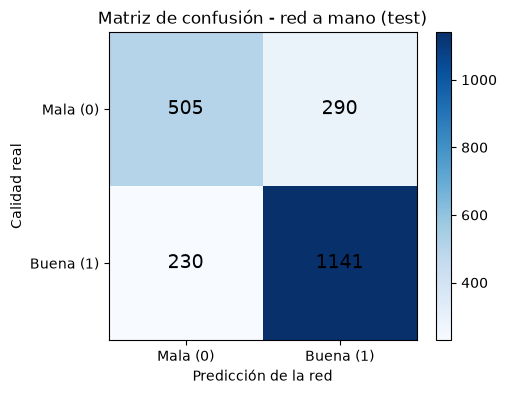

Malos acertados: 505 de 795
Buenos acertados: 1141 de 1371
Accuracy test: 0.7599261311172668


In [2]:
def graficar_accuracy(L, train_l, test_l):
    epocas = np.arange(len(train_l)) * 100 / n      

    fmt_train = {'color': 'tab:blue','ls': 'solid','lw': 1}
    fmt_test = {'color': 'tab:red','ls': 'solid','lw': 1}

    fig, (ax) = plt.subplots(1,1,figsize=(10,8))

    ax.plot(epocas, train_l, label='Train', **fmt_train)   
    ax.plot(epocas, test_l, label='Test', **fmt_test)      

    ax.grid(which='both')
    ax.legend()
    ax.set_title(f'Accuracy {L=}')
    ax.set_xlabel('epocas')                                
    ax.set_ylabel('Accuracy')

    fig.tight_layout()

def graficar_perdida(L, train_l, test_l):
    epocas = np.arange(len(train_l)) * 100 / n     

    fig, ax = plt.subplots(1, 1, figsize=(10, 8))

    ax.plot(epocas, train_l, label='Train', color='tab:blue', ls='solid', lw=1)
    ax.plot(epocas, test_l, label='Test', color='tab:red', ls='solid', lw=1)

    ax.grid(which='both')
    ax.legend()
    ax.set_title(f'Perdida (error cuadratico medio) {L=}')
    ax.set_xlabel('epocas')
    ax.set_ylabel('Perdida')

    fig.tight_layout()

pred = (forward_prop(x_test.transpose())[3] >= .5).flatten().astype(int)

vn = ((pred == 0) & (y_test == 0)).sum()   # malos clasificados como malos
fp = ((pred == 1) & (y_test == 0)).sum()   # malos clasificados como buenos
fn = ((pred == 0) & (y_test == 1)).sum()   # buenos clasificados como malos
vp = ((pred == 1) & (y_test == 1)).sum()   # buenos clasificados como buenos

matriz = np.array([[vn, fp],
                   [fn, vp]])

plt.figure(figsize=(5, 4))
plt.imshow(matriz, cmap='Blues')
plt.colorbar()
plt.xticks([0, 1], ['Mala (0)', 'Buena (1)'])
plt.yticks([0, 1], ['Mala (0)', 'Buena (1)'])
plt.xlabel('Prediccion de la red')
plt.ylabel('Calidad real')
plt.title('Matriz de confusion - red a mano (test)')
for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz[i, j], ha='center', va='center', fontsize=14)
plt.show()

print("Malos acertados:", vn, "de", vn + fp)
print("Buenos acertados:", vp, "de", vp + fn)
print("Accuracy test:", (vn + vp) / len(y_test))

***c) Ya definidas mis funciones para graficar graficamos con el eje x en "Epocas". Una "epoca" es haber recorrido todos los vinos del entrenamiento una vez. Aprox el tamaño de entrenamiento son de 4331 vinos. Entonces 1 epoca = 4331 pasos.***

*if i % 100 == 0:*

***En esta linea lo que hacemos es guardar el accuracy y perdida cada 100 pasos. Es decir, el punto 1 es el paso 100, el 2 el 200 y asi sucesivamente. Luego para pasarlo epocas hago la formula: epocas=100.k/n.***

Train (promedio ultimos 100 puntos): 0.7547194643269454
Test (promedio ultimos 100 puntos): 0.755701754385965


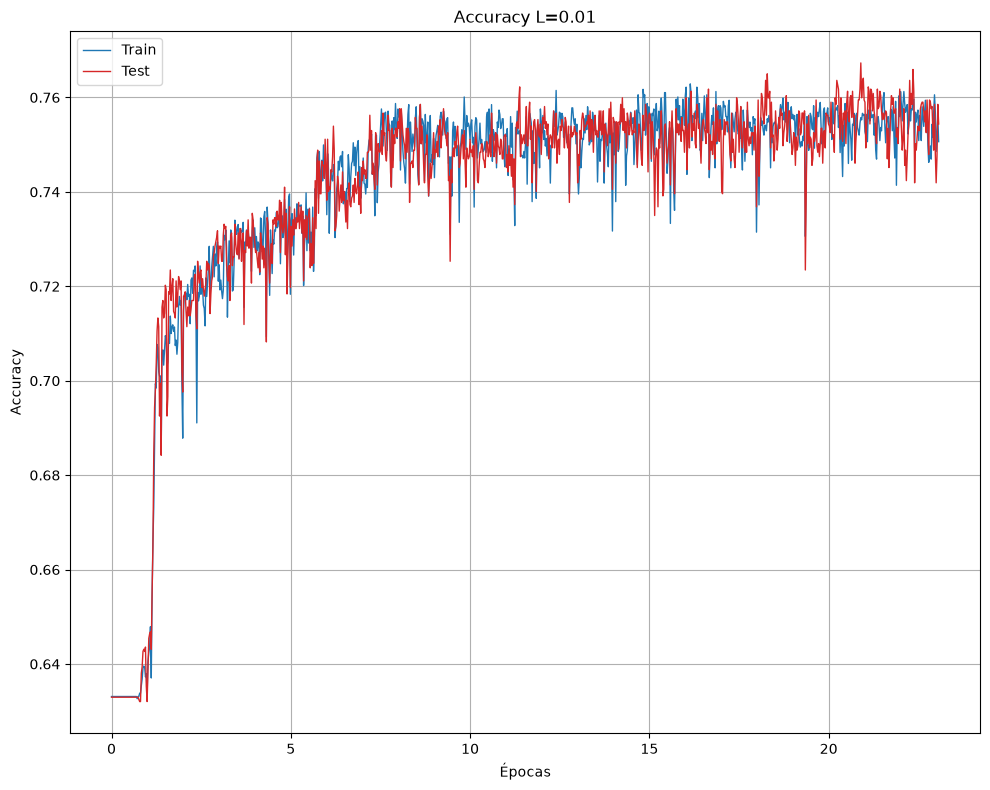

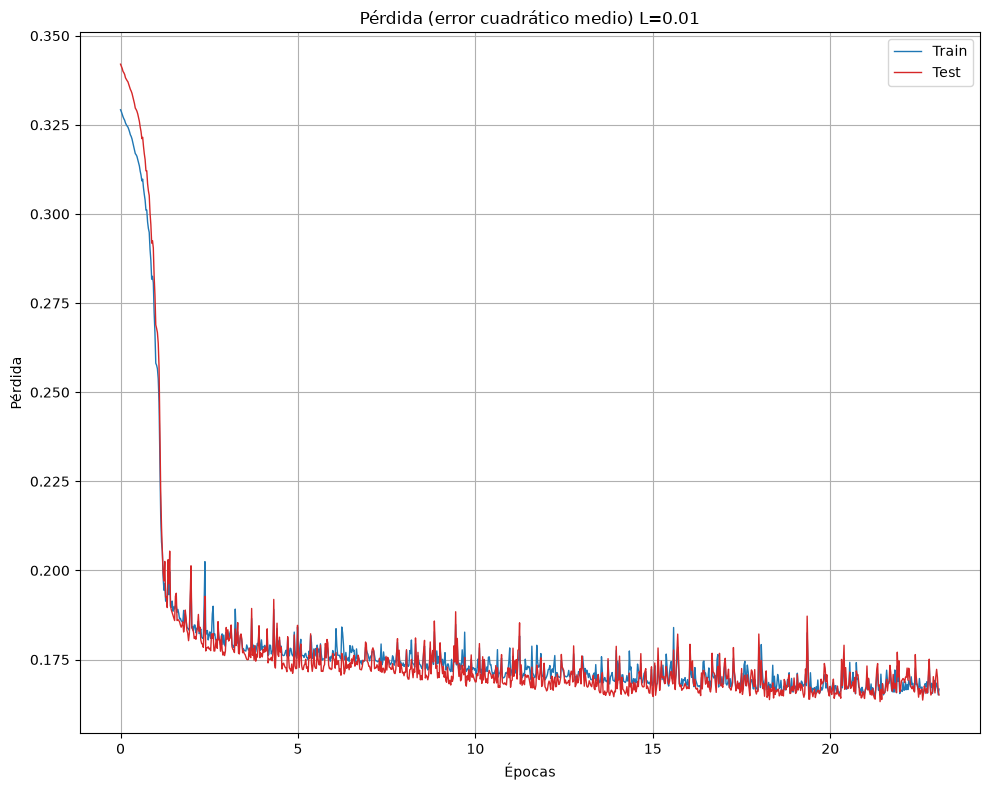

In [3]:
graficar_accuracy(L=0.01, train_l=accuracy_train_1,test_l=accuracy_test_1)
graficar_perdida(0.01, loss_train_1, loss_test_1)
print("Train (promedio ultimos 100 puntos):", np.mean(accuracy_train_1[-100:]))
print("Test (promedio ultimos 100 puntos):", np.mean(accuracy_test_1[-100:]))

***D) Para analizar si el modelo presenta overfitting se comparan las curvas de entrenamiento y de test. El sobreajuste aparece cuando la red mejora en los datos de entrenamiento pero deja de mejorar (o empeora) en los de test, es decir, cuando empieza a memorizar los vinos de entrenamiento en lugar de aprender patrones generales. En nuestro caso, las curvas de accuracy y de perdida de train y de test quedan practicamente superpuestas durante todo el entrenamiento (accuracy de aprox 75,5% en ambos conjuntos), por lo que concluimos que el modelo no presenta overfitting apreciable.***

***El punto en el que el modelo empieza a sobreajustarse se identifica en la curva de perdida: es la epoca en la que la perdida de test alcanza su minimo y luego comienza a subir, mientras que la perdida de entrenamiento sigue bajando. A partir de ese punto, entrenar mas mejora el ajuste a los datos de entrenamiento pero empeora la generalizacion. En nuestras curvas esa separacion no se observa dentro de las epocas entrenadas; solo al entrenar durante muchas mas epocas se veria un aumento leve de la perdida de test.***

***Para manejar el overfitting usariamos: early stopping, deteniendo el entrenamiento en la epoca donde la perdida de test (idealmente de un conjunto de validacion separado) deja de mejorar; regularizacion L2 (aca no usamos eso), que penaliza los pesos grandes; reducir la cantidad de neuronas de la capa oculta para disminuir la capacidad de la red; o conseguir mas datos de entrenamiento. En este trabajo, como no se observa sobreajuste, no fue necesario aplicarlos, y la red de 10 neuronas resulto un tamaño adecuado.***